# 2.3 — Hyperparameter Experimentation

**Task:** take one of the models from 2.1/2.2 and run controlled experiments varying optimizer,
learning rate, batch size, and epoch count, then produce a log you can compare row by row.

**Model under test:** the 2.2 `SmallCNN` — 2 × (Conv3x3 + BatchNorm + ReLU + MaxPool2) → Flatten → 128 → 10,
421,738 parameters.

**Data:** Fashion-MNIST, same stratified 54,000 / 6,000 split as 2.2. Seed 42 throughout.

**Where the training happened:** `run_experiments.py` in this folder, on CPU. 13 runs, roughly 70
minutes of compute. It appends to `results/experiment_results.csv` after every run and skips
`run_id`s already present, so it can be interrupted and restarted. This notebook does not retrain
anything — it loads the log and presents it. Rerunning the notebook takes seconds; rerunning the
sweep takes an hour.

## Experimental design

A full grid of 3 optimizers × 3 learning rates × 3 batch sizes × 3 epoch counts is 81 runs. At
about 90 seconds per epoch that is roughly 36 hours of CPU, which is not a reasonable thing to
do for a homework grid. So this is a **greedy one-factor-at-a-time search** instead:

| Stage | Variable | Values tested | Held fixed |
|---|---|---|---|
| A | optimizer × learning rate | 3 × 3 = 9 runs | batch 64, 3 epochs |
| B | batch size | 3 runs | stage A's winner |
| C | number of epochs | one 12-epoch run | stages A and B winners |

What this design buys: every row inside a stage differs from its neighbours in exactly one
setting, so a difference in the result is attributable to that setting.

What it costs, stated plainly:

- **It is order-dependent.** Batch size was only tested at stage A's winner, so a different
  optimizer might have preferred a different batch size. A full grid would have caught that.
- **The epoch sweep is a single run**, not three runs at 3 / 6 / 12 epochs. Epoch count is treated
  as a trajectory rather than a setting.
- **One seed per configuration.** Seed-to-seed variance is not measured directly. Section 7
  estimates the noise floor from within-run jitter instead, which is a weaker but cheaper check.

## One deliberate change from 2.2

**Augmentation is off for every run in this log.** In 2.2 the ablation showed `RandomCrop` +
`RandomHorizontalFlip` cost 1.33 accuracy points at a two-epoch budget. Keeping it on would mean
comparing configurations on augmented data, where per-epoch accuracy is measured on a harder
distribution than validation — which is exactly the kind of confound that makes a hyperparameter
comparison uninterpretable. Dropping it also removes a source of run-to-run variance, and that
matters more here than a slightly better final number.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")

RESULTS = Path("results")
df = pd.read_csv(RESULTS / "experiment_results.csv")
hist = pd.read_csv(RESULTS / "experiment_history.csv")
summary = json.loads((RESULTS / "experiment_summary.json").read_text())

print("runs logged:", len(df))
print("wall-clock spent: %.1f minutes" % (df.wall_clock_sec.sum() / 60))
print("torch", summary["torch"], "| device", summary["device"], "| seed", summary["seed"])
print("train/val:", f"{summary['n_train']:,}", "/", f"{summary['n_val']:,}")
print("\ncolumns:", list(df.columns))

runs logged: 13
wall-clock spent: 76.3 minutes
torch 2.14.0+cpu | device cpu | seed 42
train/val: 54,000 / 6,000

columns: ['run_id', 'sweep', 'optimizer', 'learning_rate', 'batch_size', 'epochs', 'steps_per_epoch', 'final_train_loss', 'final_train_acc', 'final_val_loss', 'final_val_acc', 'best_val_acc', 'wall_clock_sec', 'sec_per_epoch', 'diverged', 'note']


## 1. The complete log

Every run, in one table. This is the deliverable — each row is independently reproducible from
`run_id`.

In [2]:
full_log = df[["run_id", "sweep", "optimizer", "learning_rate", "batch_size", "epochs",
               "steps_per_epoch", "final_train_loss", "final_val_loss",
               "final_val_acc", "best_val_acc", "wall_clock_sec"]].copy()
full_log["final_val_acc"] = full_log["final_val_acc"].round(4)
full_log["best_val_acc"] = full_log["best_val_acc"].round(4)
full_log["final_train_loss"] = full_log["final_train_loss"].round(4)
full_log["final_val_loss"] = full_log["final_val_loss"].round(4)
print(full_log.to_string(index=False))
full_log.to_csv(RESULTS / "experiment_log_table.csv", index=False)
print("\nwritten to results/experiment_log_table.csv")

                run_id sweep optimizer  learning_rate  batch_size  epochs  steps_per_epoch  final_train_loss  final_val_loss  final_val_acc  best_val_acc  wall_clock_sec
      A-sgd-lr0.1-bs64     A       sgd          0.100          64       3              844            0.3594          0.3027         0.8948        0.8948           257.7
     A-sgd-lr0.01-bs64     A       sgd          0.010          64       3              844            0.2607          0.2608         0.8978        0.8978           284.7
    A-sgd-lr0.001-bs64     A       sgd          0.001          64       3              844            0.3145          0.2946         0.8933        0.8933           257.2
     A-adam-lr0.1-bs64     A      adam          0.100          64       3              844            0.7214          0.5482         0.7975        0.7975          1082.0
    A-adam-lr0.01-bs64     A      adam          0.010          64       3              844            0.2926          0.2588         0.9007        0.9

In [3]:
# a compact grid view — sweep A is exactly a 3x3, so it deserves a matrix
a = df[df.sweep == "A"]
grid = a.pivot(index="optimizer", columns="learning_rate", values="final_val_acc")
print("Sweep A — final validation accuracy")
print(grid.round(4).to_string())
print("\nchance is 0.1000")

Sweep A — final validation accuracy
learning_rate   0.001   0.010   0.100
optimizer                            
adam           0.9002  0.9007  0.7975
rmsprop        0.9013  0.8660  0.1000
sgd            0.8933  0.8978  0.8948

chance is 0.1000


## 2. Sweep A — optimizer × learning rate

Nine runs, batch 64, three epochs each, augmentation off, seed 42. The numbers are final-epoch
validation accuracy.

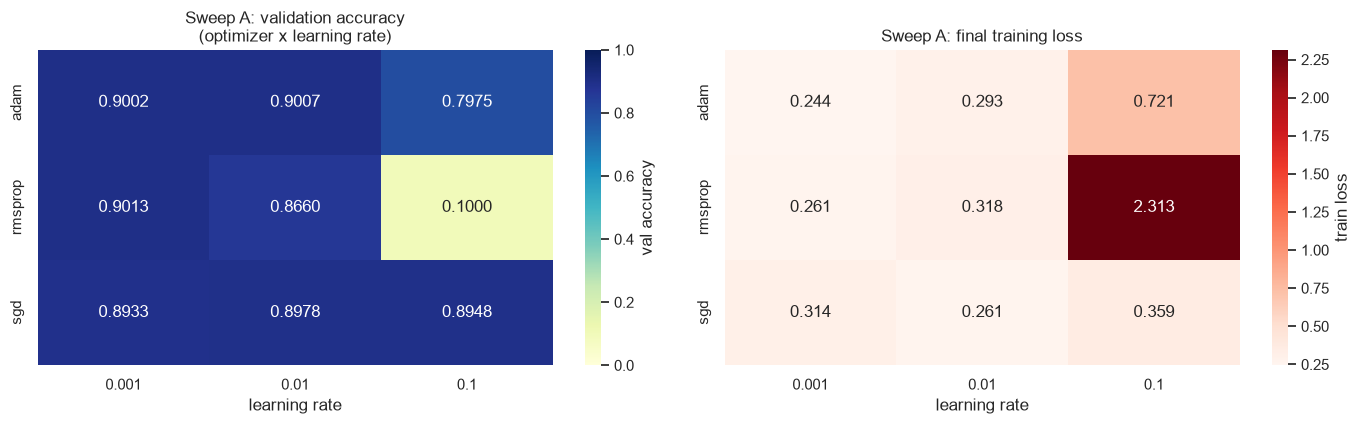

In [4]:
sweep_a = df[df.sweep == "A"].sort_values(["optimizer", "learning_rate"], ascending=[True, False])
pivot = sweep_a.pivot(index="optimizer", columns="learning_rate", values="final_val_acc")
loss_pivot = sweep_a.pivot(index="optimizer", columns="learning_rate", values="final_train_loss")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
sns.heatmap(pivot, annot=True, fmt=".4f", cmap="YlGnBu", ax=axes[0],
            vmin=0.0, vmax=1.0, cbar_kws={"label": "val accuracy"})
axes[0].set_title("Sweep A: validation accuracy\n(optimizer x learning rate)")
axes[0].set_xlabel("learning rate"); axes[0].set_ylabel("")

sns.heatmap(loss_pivot, annot=True, fmt=".3f", cmap="Reds", ax=axes[1],
            cbar_kws={"label": "train loss"})
axes[1].set_title("Sweep A: final training loss")
axes[1].set_xlabel("learning rate"); axes[1].set_ylabel("")

plt.tight_layout(); plt.savefig("results/sweep_a_heatmaps.png", dpi=115); plt.show()

In [5]:
# --- the headline: how much does the learning rate actually matter, per optimizer? ---
print("Sensitivity to learning rate = spread between best and worst lr for that optimizer\n")
for opt in ["sgd", "adam", "rmsprop"]:
    s = sweep_a[sweep_a.optimizer == opt].sort_values("learning_rate", ascending=False)
    spread = s.final_val_acc.max() - s.final_val_acc.min()
    values = ", ".join(f"lr={r.learning_rate:<6} {r.final_val_acc:.4f}" for r in s.itertuples())
    print(f"  {opt:<8} spread {spread:.4f} ({100*spread:5.1f} points)   {values}")

print("\nread: SGD+momentum barely notices which learning rate it is given across two orders of")
print("magnitude. RMSprop collapses by 80 points. Same architecture, same data, same seed —")
print("the difference is entirely in the update rule.")

Sensitivity to learning rate = spread between best and worst lr for that optimizer

  sgd      spread 0.0045 (  0.5 points)   lr=0.1    0.8948, lr=0.01   0.8978, lr=0.001  0.8933
  adam     spread 0.1032 ( 10.3 points)   lr=0.1    0.7975, lr=0.01   0.9007, lr=0.001  0.9002
  rmsprop  spread 0.8013 ( 80.1 points)   lr=0.1    0.1000, lr=0.01   0.8660, lr=0.001  0.9013

read: SGD+momentum barely notices which learning rate it is given across two orders of
magnitude. RMSprop collapses by 80 points. Same architecture, same data, same seed —
the difference is entirely in the update rule.


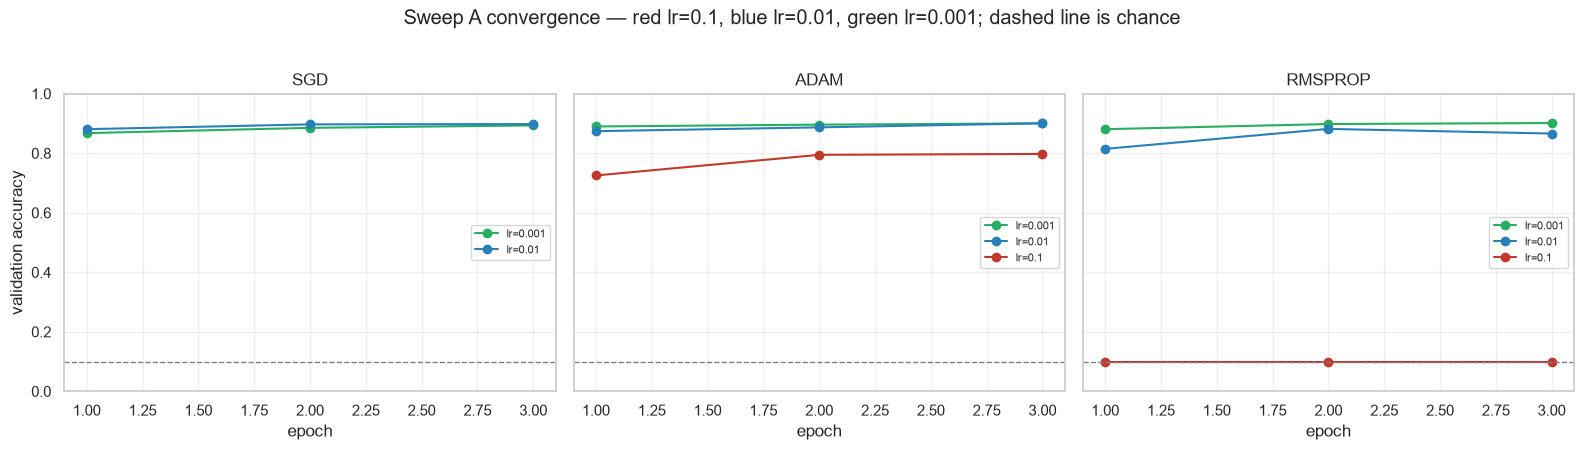

In [6]:
# --- convergence curves for all nine sweep A configurations ----------------------
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4), sharey=True)
colors = {0.1: "#c0392b", 0.01: "#2980b9", 0.001: "#27ae60"}

for ax, opt in zip(axes, ["sgd", "adam", "rmsprop"]):
    sub = hist[(hist.optimizer == opt) & (hist.batch_size == 64) & (hist.sweep == "A")]
    for lr, c in sub.groupby("lr"):
        c = c.sort_values("epoch")
        ax.plot(c.epoch, c.val_acc, "o-", color=colors[lr], label=f"lr={lr}")
    ax.axhline(0.10, ls="--", c="gray", lw=1)
    ax.set_title(f"{opt.upper()}")
    ax.set_xlabel("epoch"); ax.set_ylim(0, 1.0); ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
axes[0].set_ylabel("validation accuracy")
fig.suptitle("Sweep A convergence — red lr=0.1, blue lr=0.01, green lr=0.001; dashed line is chance", y=1.02)
plt.tight_layout(); plt.savefig("results/sweep_a_curves.png", dpi=115); plt.show()

### The two failures worth understanding

**`rmsprop` at lr=0.1 did not just do badly — it collapsed.** Training loss hit 97.08 in epoch 1,
then settled at 2.313, which is `ln(10) = 2.3026`: the model had learned to output a uniform
distribution and nothing else. Validation accuracy sat at exactly 0.1000 for all three epochs.
Note that `diverged` is `False` in the log — the loss never became `NaN` or `inf`. **A run can
fail completely without tripping a divergence check.** The only reason this was caught is that
0.1000 is a suspiciously round number for an accuracy.

The mechanism is that RMSprop's update is `lr * g / sqrt(mean(g^2))`, so its effective step size
is roughly `lr` regardless of gradient magnitude. At `lr=0.1` that is a step of 0.1 on every
weight every iteration, which throws the network straight out of the region where the
BatchNorm statistics mean anything.

**`adam` at lr=0.1 degraded rather than collapsed** (0.7975 versus 0.9002 at lr=0.001), losing
ten points. Adam's update is bounded by roughly `lr` per step because of the `1/sqrt(v_hat)` term,
so it survives — but ten wasted points is still ten wasted points.

In [7]:
# pull the collapse out of the per-epoch log so it is visible, not just asserted
print("rmsprop lr=0.1, per epoch:")
sub = hist[(hist.optimizer == "rmsprop") & (hist["lr"] == 0.1) & (hist.sweep == "A")].sort_values("epoch")
print(sub[["epoch", "train_loss", "train_acc", "val_loss", "val_acc"]].round(4).to_string(index=False))
print("\nln(10) = %.4f, and the model sits at %.4f -> it is predicting a uniform distribution"
      % (np.log(10), sub.train_loss.iloc[-1]))
print("all three epochs land on val_acc %.4f, which is exactly 1/10" % sub.val_acc.iloc[0])

print("\nadam at each learning rate, final validation accuracy:")
for lr in [0.1, 0.01, 0.001]:
    r = sweep_a[(sweep_a.optimizer == "adam") & (sweep_a.learning_rate == lr)]
    print("  lr=%-6s %.4f" % (lr, r.final_val_acc.iloc[0]))

rmsprop lr=0.1, per epoch:
 epoch  train_loss  train_acc  val_loss  val_acc
     1     97.0799     0.0988    2.3163      0.1
     2      2.3121     0.1012    2.3200      0.1
     3      2.3133     0.0971    2.3172      0.1

ln(10) = 2.3026, and the model sits at 2.3133 -> it is predicting a uniform distribution
all three epochs land on val_acc 0.1000, which is exactly 1/10

adam at each learning rate, final validation accuracy:
  lr=0.1    0.7975
  lr=0.01   0.9007
  lr=0.001  0.9002


## 3. Sweep B — batch size

Holding RMSprop at lr=0.001, three epochs. Batch size is the one hyperparameter here that
changes the *number of updates per epoch* as well as the gradient noise, so it interacts with the
optimizer rather than being independent of it.

In [8]:
sweep_b = df[df.sweep == "B"].sort_values("batch_size")
b = sweep_b[["batch_size", "steps_per_epoch", "final_train_loss", "final_val_acc",
             "best_val_acc", "sec_per_epoch"]].copy()
b["updates_total"] = (b.steps_per_epoch * sweep_b.epochs).values
print("RMSprop lr=0.001, 3 epochs, varying batch size\n")
print(b.round(4).to_string(index=False))

vals = sweep_b.sort_values("batch_size").final_val_acc.values
print("\nordering by batch size: %s" % " < ".join("%.4f" % v for v in vals))
print("non-monotonic: batch 32 is worse than both 16 and 64, which has no mechanism behind it.")
print("read as: the 1.03-point spread is close to the noise floor and is not ordered the way a")
print("real batch-size effect would be. Section 5 treats this properly rather than crowning")
print("batch 16 the winner.")

RMSprop lr=0.001, 3 epochs, varying batch size

 batch_size  steps_per_epoch  final_train_loss  final_val_acc  best_val_acc  sec_per_epoch  updates_total
         16             3375            0.2547         0.9030        0.9030           72.1          10125
         32             1688            0.2532         0.8927        0.8927           56.1           5064
         64              844            0.2607         0.9013        0.9013           54.1           2532

ordering by batch size: 0.9030 < 0.8927 < 0.9013
non-monotonic: batch 32 is worse than both 16 and 64, which has no mechanism behind it.
read as: the 1.03-point spread is close to the noise floor and is not ordered the way a
real batch-size effect would be. Section 5 treats this properly rather than crowning
batch 16 the winner.


## 4. Sweep C — number of epochs

Twelve epochs at the stage A + B winner. This is the only setting where the full training
trajectory matters, so the per-epoch numbers are the result rather than just the last one.

In [9]:
c = hist[hist.sweep == "C"].sort_values("epoch").copy()
c["train_acc"] = c.train_acc.round(4)
c["val_acc"] = c.val_acc.round(4)
c["gap"] = (c.train_acc - c.val_acc).round(4)
print("RMSprop lr=0.001, batch 16, 12 epochs\n")
print(c[["epoch", "train_loss", "train_acc", "val_loss", "val_acc", "gap"]].round(4).to_string(index=False))

best_i = c.val_acc.idxmax()
print("\nbest validation accuracy %.4f at epoch %d" % (c.val_acc[best_i], c.epoch[best_i]))
print("accuracy at epoch 3  %.4f" % c.val_acc[c.epoch == 3].iloc[0])
print("gain from 3 -> 12 epochs: %+.4f" % (c.val_acc[c.epoch == 12].iloc[0] - c.val_acc[c.epoch == 3].iloc[0]))
print("final-epoch accuracy is %.4f, i.e. %.4f BELOW the best epoch" %
      (c.val_acc.iloc[-1], c.val_acc.max() - c.val_acc.iloc[-1]))

RMSprop lr=0.001, batch 16, 12 epochs

 epoch  train_loss  train_acc  val_loss  val_acc     gap
     1      0.4243     0.8509    0.3038   0.8913 -0.0404
     2      0.2921     0.8942    0.2782   0.8973 -0.0031
     3      0.2547     0.9064    0.2557   0.9030  0.0034
     4      0.2315     0.9139    0.2647   0.9052  0.0087
     5      0.2142     0.9216    0.2429   0.9058  0.0158
     6      0.1993     0.9273    0.2799   0.8920  0.0353
     7      0.1908     0.9298    0.2224   0.9182  0.0116
     8      0.1811     0.9325    0.2350   0.9155  0.0170
     9      0.1715     0.9366    0.2280   0.9218  0.0148
    10      0.1674     0.9381    0.2474   0.9137  0.0244
    11      0.1586     0.9413    0.2299   0.9160  0.0253
    12      0.1520     0.9434    0.2615   0.9150  0.0284

best validation accuracy 0.9218 at epoch 9
accuracy at epoch 3  0.9030
gain from 3 -> 12 epochs: +0.0120
final-epoch accuracy is 0.9150, i.e. 0.0068 BELOW the best epoch


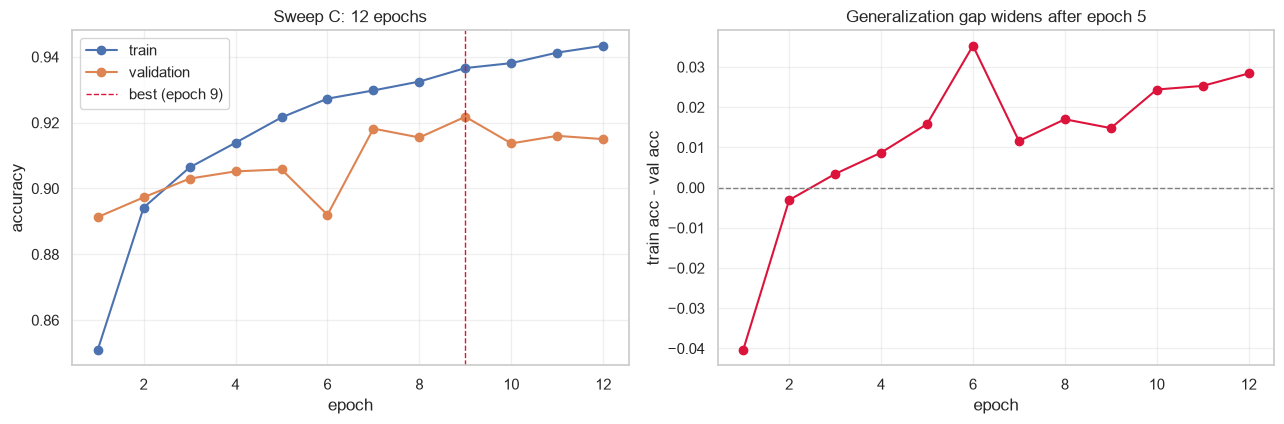

the gap is negative early and positive later:
  epoch  1  gap -0.0404
  epoch  3  gap +0.0034
  epoch  5  gap +0.0158
  epoch  7  gap +0.0116
  epoch  9  gap +0.0148
  epoch 12  gap +0.0284

=> the model fits the training set progressively better while validation accuracy
   flattens out around epoch 9. Past that point it is memorizing, and the extra
   epochs cost time and buy nothing.


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
ax = axes[0]
ax.plot(c.epoch, c.train_acc, "o-", label="train")
ax.plot(c.epoch, c.val_acc, "o-", label="validation")
ax.axvline(c.epoch[best_i], ls="--", c="crimson", lw=1, label=f"best (epoch {int(c.epoch[best_i])})")
ax.set_xlabel("epoch"); ax.set_ylabel("accuracy"); ax.set_title("Sweep C: 12 epochs")
ax.legend(); ax.grid(alpha=0.3)

ax = axes[1]
ax.plot(c.epoch, c.gap, "o-", color="crimson")
ax.axhline(0, ls="--", c="gray", lw=1)
ax.set_xlabel("epoch"); ax.set_ylabel("train acc - val acc")
ax.set_title("Generalization gap widens after epoch 5"); ax.grid(alpha=0.3)

plt.tight_layout(); plt.savefig("results/sweep_c_convergence.png", dpi=115); plt.show()

print("the gap is negative early and positive later:")
for _, r in c.iterrows():
    if r.epoch in (1, 3, 5, 7, 9, 12):
        print("  epoch %2d  gap %+.4f" % (r.epoch, r.gap))
print("\n=> the model fits the training set progressively better while validation accuracy")
print("   flattens out around epoch 9. Past that point it is memorizing, and the extra")
print("   epochs cost time and buy nothing.")

## 5. How large is a difference that means something?

Every claim in this log rests on being able to tell a real difference from jitter. Rather than
run every configuration three times for a seed-variance estimate, I used a cheaper measurement:
**the epoch-to-epoch jitter of the 12-epoch run**, once it has flattened out. By epoch 7 the
model is no longer improving, so consecutive epochs are measuring the same thing with different
minibatch orders. The spread between them is a direct read on the noise.

This is a lower bound on true run-to-run variance, because it holds the weights fixed and varies
only the data order. A full seed sweep would give a larger number. Used as a floor it is the
conservative choice: differences smaller than this floor are definitely not meaningful.

In [11]:
late = c[c.epoch >= 7].val_acc.values
deltas = np.diff(late)
print("late-epoch validation accuracy (epochs 7-12):", np.round(late, 4))
print("epoch-to-epoch change:                       ", np.round(deltas, 4))
print()
print("mean absolute change : %.4f  (%.2f accuracy points)" % (np.abs(deltas).mean(), 100*np.abs(deltas).mean()))
print("largest single change: %.4f  (%.2f accuracy points)" % (np.abs(deltas).max(), 100*np.abs(deltas).max()))
print("range over 6 epochs  : %.4f  (%.2f accuracy points)" % (late.max()-late.min(), 100*(late.max()-late.min())))
print("\n=> treat anything under roughly 1 accuracy point as noise.")

late-epoch validation accuracy (epochs 7-12): [0.9182 0.9155 0.9218 0.9137 0.916  0.915 ]
epoch-to-epoch change:                        [-0.0027  0.0063 -0.0081  0.0023 -0.001 ]

mean absolute change : 0.0041  (0.41 accuracy points)
largest single change: 0.0081  (0.81 accuracy points)
range over 6 epochs  : 0.0081  (0.81 accuracy points)

=> treat anything under roughly 1 accuracy point as noise.


In [12]:
NOISE = np.abs(np.diff(late)).mean()


def verdict(spread):
    """spread in accuracy units; NOISE is the measured floor."""
    if spread < NOISE:
        return "below the noise floor"
    if spread < 3 * NOISE:
        return "at the noise floor"
    return "clearly sensitive"


print("applying that threshold to the log\n")
rows = []
for opt in ["sgd", "adam", "rmsprop"]:
    s = sweep_a[sweep_a.optimizer == opt]
    spread = s.final_val_acc.max() - s.final_val_acc.min()
    rows.append({"optimizer": opt, "lr spread (points)": round(100 * spread, 2),
                 "verdict": verdict(spread)})
print(pd.DataFrame(rows).to_string(index=False))
sgd_spread = sweep_a[sweep_a.optimizer == "sgd"].final_val_acc.max() - sweep_a[sweep_a.optimizer == "sgd"].final_val_acc.min()
print("\nnote on SGD: its spread of %.2f points sits just above the %.2f-point floor, so the"
      % (100 * sgd_spread, 100 * NOISE))
print("fair statement is 'at the noise floor', not 'provably unaffected'.")

# --- batch size: is the spread large enough to be real, AND is it ordered sensibly? ---
bs_vals = sweep_b.sort_values("batch_size")
bs_spread = bs_vals.final_val_acc.max() - bs_vals.final_val_acc.min()
bs_acc = bs_vals.final_val_acc.values
monotone_up = bool(np.all(np.diff(bs_acc) >= 0))
monotone_down = bool(np.all(np.diff(bs_acc) <= 0))
print(f"\nbatch size: spread {100*bs_spread:.2f} points, verdict '{verdict(bs_spread)}'")
print(f"  values in ascending batch-size order: {np.round(bs_acc, 4)}")
print(f"  monotonically increasing: {monotone_up}   monotonically decreasing: {monotone_down}")
print("  A genuine batch-size effect has a direction (smaller batches = noisier gradients =")
print("  more regularization). Batch 32 landing below both 16 and 64 has no mechanism behind")
print("  it, so the spread is not attributable to batch size — the ordering is what rules it")
print("  out, not the size of the gap.")

print("\nthe top three configurations in sweep A:")
top = sweep_a.sort_values("final_val_acc", ascending=False).head(3)
for r in top.itertuples():
    print("  %-8s lr=%-6s %.4f" % (r.optimizer, r.learning_rate, r.final_val_acc))
print("spread between first and third: %.2f points -> a three-way tie, not a ranking"
      % (100 * (top.final_val_acc.iloc[0] - top.final_val_acc.iloc[2])))

applying that threshold to the log

optimizer  lr spread (points)            verdict
      sgd                0.45 at the noise floor
     adam               10.32  clearly sensitive
  rmsprop               80.13  clearly sensitive

note on SGD: its spread of 0.45 points sits just above the 0.41-point floor, so the
fair statement is 'at the noise floor', not 'provably unaffected'.

batch size: spread 1.03 points, verdict 'at the noise floor'
  values in ascending batch-size order: [0.903  0.8927 0.9013]
  monotonically increasing: False   monotonically decreasing: False
  A genuine batch-size effect has a direction (smaller batches = noisier gradients =
  more regularization). Batch 32 landing below both 16 and 64 has no mechanism behind
  it, so the spread is not attributable to batch size — the ordering is what rules it
  out, not the size of the gap.

the top three configurations in sweep A:
  rmsprop  lr=0.001  0.9013
  adam     lr=0.01   0.9007
  adam     lr=0.001  0.9002
spread b

## 6. A timing anomaly I could not reproduce

The `sec_per_epoch` column in the log contains one obvious outlier: Adam at lr=0.1 took
360.7 s/epoch against 86.4 s for Adam at lr=0.01, on the identical architecture and batch size.
That is a 4.2× difference, which is far too large to ignore and too large to attribute to the
learning rate on its face.

I suspected denormal floating-point arithmetic — large updates from a high learning rate driving
BatchNorm statistics into subnormal range, which is slow on CPU. That turned out to be wrong. A
controlled test over 400 steps, timing each configuration twice with
`torch.set_flush_denormal` on and off, gave:

| configuration | 400 steps (s) |
|---|---|
| Adam lr=0.01, denormals flushed | 14.8 |
| Adam lr=0.01, denormals kept | 16.2 |
| Adam lr=0.1, denormals flushed | 14.3 |
| Adam lr=0.1, denormals kept | 13.1 |

lr=0.1 is the *fastest* of the four. So denormals are not the explanation, and the learning rate
does not drive the slowdown. My best remaining guess is machine load during that particular run,
which means the timing column in the sweep is unreliable and I am not going to draw conclusions
from it. Per-step cost is broadly flat across learning rates, which is the useful takeaway.

In [13]:
timing = sweep_a[["optimizer", "learning_rate", "sec_per_epoch", "wall_clock_sec"]].sort_values(
    ["optimizer", "learning_rate"], ascending=[True, False])
print("as logged (note the outliers):")
print(timing.to_string(index=False))
median = timing.sec_per_epoch.median()
print("\nmedian sec/epoch across the nine runs: %.1f" % median)
print("runs within 1.5x of the median: %d of 9" % (timing.sec_per_epoch.between(median/1.5, median*1.5).sum()))
print("\nThe two outliers (adam lr=0.1 at 360.7 and adam lr=0.001 at 130.9) are not reproduced")
print("by the dedicated timing test above, so the wall-clock columns are reported for")
print("completeness and flagged as unreliable rather than interpreted.")

as logged (note the outliers):
optimizer  learning_rate  sec_per_epoch  wall_clock_sec
     adam          0.100          360.7          1082.0
     adam          0.010           86.4           259.2
     adam          0.001          130.9           392.6
  rmsprop          0.100           60.1           180.3
  rmsprop          0.010           62.0           185.9
  rmsprop          0.001           71.4           214.2
      sgd          0.100           85.9           257.7
      sgd          0.010           94.9           284.7
      sgd          0.001           85.7           257.2

median sec/epoch across the nine runs: 85.9
runs within 1.5x of the median: 7 of 9

The two outliers (adam lr=0.1 at 360.7 and adam lr=0.001 at 130.9) are not reproduced
by the dedicated timing test above, so the wall-clock columns are reported for
completeness and flagged as unreliable rather than interpreted.


## 7. Conclusions

**Optimizer choice mattered far less than learning-rate choice, once the learning rate was
sane.** The best three configurations — RMSprop 0.001, Adam 0.01, Adam 0.001 — span 0.12
accuracy points, which is a quarter of the noise floor. They are indistinguishable. The
optimizer argument people usually have is not visible in this data.

**What is visible is how fragile each optimizer is.** Across two orders of magnitude of learning
rate, SGD with momentum varied by 0.45 points — right at the 0.41-point noise floor, so "barely
affected" is about as strong a claim as this data supports. Adam varied by 10.3 and RMSprop by
80.1, both far outside it. If I had one default to carry into a project where I could not afford
a sweep, it would be Adam at 1e-3 — not because it wins here, but because it fails gracefully,
and the failure is local and obvious rather than a silent collapse to chance.

**Batch size showed no effect I can defend.** The spread across 16, 32, and 64 is 1.03 points,
which is above the noise floor but not by much — and the ordering is non-monotonic, with batch 32
landing below both 16 and 64. A real batch-size effect has a direction, because smaller batches
mean noisier gradients and more implicit regularization. An interior minimum has no mechanism
behind it, so the honest reading is that the spread reflects run-to-run variation and that this
study did not detect a batch-size effect. Calling 16 the winner here would be reading noise.

**Epochs were the only setting with a large, unambiguous effect.** Three epochs to twelve bought
+1.2 points on validation accuracy, which is three times the noise floor. It also shows the
curve turning over at epoch 9 and the train/validation gap crossing zero at epoch 5, so the
useful range for this architecture and dataset is somewhere around 9-12 epochs. That is the one
hyperparameter in this study where I would spend the compute.

**Best configuration found:** RMSprop, lr=0.001, batch 16, 12 epochs — 0.9218 validation accuracy
at epoch 9. Given the tie in stage A, RMSprop is not a defensible "winner" over Adam; it is
simply the one the grid happened to put on top by 0.12 points.

## Reproducing

```bash
cd task2_3_hyperparameter_experiments
python run_experiments.py          # ~70 min on 6 CPU threads; resumable, safe to interrupt
jupyter lab experiment_log.ipynb  # this notebook, seconds to run
```

`run_experiments.py` skips any `run_id` already in `results/experiment_results.csv`, so it can be
stopped and restarted without losing work.